# 01 — Exploration des données ADS-B

## Objectif du notebook

Ce notebook sert à **comprendre les données brutes** avant de faire le nettoyage, le resampling ou le feature engineering.

Nous allons analyser les 8 fichiers horaires placés dans `data/raw/` afin de répondre aux questions suivantes :

1. Les fichiers sont-ils bien présents ?
2. Ont-ils la même structure ?
3. Combien de lignes et d’avions contiennent-ils ?
4. Quelle période temporelle couvrent-ils ?
5. Quelles colonnes contiennent des valeurs manquantes ?
6. Existe-t-il des valeurs physiquement impossibles ?
7. Les données brutes ressemblent-elles bien à des trajectoires ?

## Ce que ce notebook ne fait pas

Dans ce notebook, nous ne faisons pas encore :

- nettoyage final ;
- concaténation finale des données propres ;
- resampling temporel ;
- feature engineering ;
- création des targets futures ;
- normalisation ;
- PCA ;
- modèles ML ou DL.

Ces étapes seront faites dans les notebooks suivants.

# 1. Initialisation de l’environnement

Nous commençons par connecter Google Drive et importer les bibliothèques nécessaires.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
from collections import Counter
import gc

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# 2. Définition des chemins du projet

Nous définissons les chemins principaux du projet pour éviter d’écrire des chemins longs plusieurs fois.

In [4]:
PROJECT_DIR = Path("/content/drive/MyDrive/aircraft-trajectory-prediction")

RAW_DIR = PROJECT_DIR / "data" / "raw"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

print("Projet existe       :", PROJECT_DIR.exists())
print("Dossier data/raw    :", RAW_DIR.exists())
print("Dossier results     :", RESULTS_DIR.exists())

Projet existe       : True
Dossier data/raw    : True
Dossier results     : True


**Résultat attendu :** les trois lignes doivent afficher `True`.

Si `RAW_DIR` affiche `False`, cela signifie que le chemin du projet ou le nom du dossier est incorrect.

# 3. Vérification des fichiers bruts disponibles

Nous vérifions maintenant que les 8 fichiers CSV horaires sont bien présents dans `data/raw/`.

In [5]:
csv_files = sorted(list(RAW_DIR.glob("*.csv")) + list(RAW_DIR.glob("*.csv.gz")))

print("Nombre de fichiers CSV trouvés :", len(csv_files))

for file in csv_files:
    print("-", file.name)

if len(csv_files) == 0:
    raise FileNotFoundError("Aucun fichier CSV trouvé dans data/raw/. Vérifiez le dossier.")

Nombre de fichiers CSV trouvés : 8
- states_2017-07-03-10.csv
- states_2017-07-03-11.csv
- states_2017-07-03-12.csv
- states_2017-07-03-13.csv
- states_2017-07-03-14.csv
- states_2017-07-03-15.csv
- states_2017-07-03-16.csv
- states_2017-07-03-17.csv


**Lecture du résultat :**

- Si le nombre affiché est `8`, les fichiers attendus sont bien détectés.
- Si le nombre est différent de `8`, il faut vérifier que tous les fichiers ont bien été déposés dans `data/raw/`.

# 4. Analyse de la structure des fichiers

Avant toute concaténation ou traitement, nous vérifions que les fichiers ont la même structure, c’est-à-dire les mêmes colonnes.

Pour éviter de charger inutilement tous les fichiers en mémoire, nous lisons seulement les 1000 premières lignes de chaque fichier.

In [6]:
columns_summary = []

for file in csv_files:
    df_sample = pd.read_csv(file, nrows=1000)

    columns_summary.append({
        "file": file.name,
        "n_columns": df_sample.shape[1],
        "columns": list(df_sample.columns)
    })

columns_df = pd.DataFrame(columns_summary)
columns_df[["file", "n_columns"]]

,file,n_columns
0,states_2017-07-03-10.csv,16
1,states_2017-07-03-11.csv,16
2,states_2017-07-03-12.csv,16
3,states_2017-07-03-13.csv,16
4,states_2017-07-03-14.csv,16
5,states_2017-07-03-15.csv,16
6,states_2017-07-03-16.csv,16
7,states_2017-07-03-17.csv,16


In [7]:
# Afficher les colonnes du premier fichier comme référence
reference_columns = columns_summary[0]["columns"]

print("Colonnes du premier fichier :")
for col in reference_columns:
    print("-", col)

Colonnes du premier fichier :
- time
- icao24
- lat
- lon
- velocity
- heading
- vertrate
- callsign
- onground
- alert
- spi
- squawk
- baroaltitude
- geoaltitude
- lastposupdate
- lastcontact


In [8]:
# Vérifier si tous les fichiers ont exactement les mêmes colonnes
same_structure = True

for item in columns_summary:
    if item["columns"] != reference_columns:
        same_structure = False
        print("Structure différente détectée dans :", item["file"])

print("Tous les fichiers ont la même structure :", same_structure)

Tous les fichiers ont la même structure : True


**Lecture du résultat :**

- Si `same_structure = True`, nous pouvons appliquer le même pipeline de traitement aux 8 fichiers.
- Si `same_structure = False`, il faudra identifier les fichiers qui ont une structure différente avant de continuer.

# 5. Colonnes importantes pour le projet

Dans cette section, nous ne faisons pas encore de sélection définitive des colonnes.

Nous vérifions seulement que les colonnes nécessaires à la prédiction de trajectoire existent bien dans les fichiers.

Les colonnes attendues sont :

| Colonne | Rôle |
|---|---|
| `time` | instant de l’observation |
| `icao24` | identifiant unique de l’avion |
| `lat` | latitude |
| `lon` | longitude |
| `velocity` | vitesse horizontale |
| `heading` | direction de déplacement |
| `vertrate` | vitesse verticale |
| `baroaltitude` | altitude barométrique |
| `geoaltitude` | altitude géométrique |

In [9]:
EXPECTED_COLUMNS = [
    "time",
    "icao24",
    "lat",
    "lon",
    "velocity",
    "heading",
    "vertrate",
    "baroaltitude",
    "geoaltitude"
]

expected_columns_check = []

for file in csv_files:
    file_columns = pd.read_csv(file, nrows=5).columns.tolist()
    missing_cols = [col for col in EXPECTED_COLUMNS if col not in file_columns]

    expected_columns_check.append({
        "file": file.name,
        "missing_expected_columns": missing_cols,
        "all_expected_columns_present": len(missing_cols) == 0
    })

expected_columns_df = pd.DataFrame(expected_columns_check)
expected_columns_df

,file,missing_expected_columns,all_expected_columns_present
0,states_2017-07-03-10.csv,[],True
1,states_2017-07-03-11.csv,[],True
2,states_2017-07-03-12.csv,[],True
3,states_2017-07-03-13.csv,[],True
4,states_2017-07-03-14.csv,[],True
5,states_2017-07-03-15.csv,[],True
6,states_2017-07-03-16.csv,[],True
7,states_2017-07-03-17.csv,[],True


**Lecture du résultat :**

La colonne `all_expected_columns_present` doit être `True` pour chaque fichier.

Si une colonne attendue manque, il faudra adapter le nettoyage dans le notebook suivant.

# 6. Analyse globale fichier par fichier

Nous lisons chaque fichier une seule fois afin de calculer plusieurs résumés :

- volume de données ;
- période temporelle ;
- nombre d’avions ;
- valeurs manquantes ;
- valeurs impossibles ;
- disponibilité de l’altitude.

Cette cellule peut prendre quelques minutes selon la taille des fichiers.

In [10]:
raw_overview = []
missing_records = []
invalid_records = []
altitude_records = []
aircraft_sets = {}

for file in csv_files:
    print("Analyse du fichier :", file.name)

    df = pd.read_csv(file)

    # Résumé général
    overview_row = {
        "file": file.name,
        "n_rows": len(df),
        "n_columns": df.shape[1]
    }

    # Nombre d'avions
    if "icao24" in df.columns:
        overview_row["n_aircraft"] = df["icao24"].nunique()
        aircraft_sets[file.name] = set(df["icao24"].dropna().unique())
    else:
        overview_row["n_aircraft"] = np.nan
        aircraft_sets[file.name] = set()

    # Période temporelle
    if "time" in df.columns:
        min_time = df["time"].min()
        max_time = df["time"].max()

        overview_row["min_time"] = min_time
        overview_row["max_time"] = max_time
        overview_row["min_datetime"] = pd.to_datetime(min_time, unit="s")
        overview_row["max_datetime"] = pd.to_datetime(max_time, unit="s")
        overview_row["duration_minutes"] = round((max_time - min_time) / 60, 2)
    else:
        overview_row["min_time"] = np.nan
        overview_row["max_time"] = np.nan
        overview_row["min_datetime"] = pd.NaT
        overview_row["max_datetime"] = pd.NaT
        overview_row["duration_minutes"] = np.nan

    raw_overview.append(overview_row)

    # Valeurs manquantes par colonne
    for col in df.columns:
        missing_records.append({
            "file": file.name,
            "column": col,
            "missing_count": df[col].isna().sum(),
            "missing_pct": df[col].isna().mean() * 100
        })

    # Valeurs impossibles pour les variables principales
    invalid_row = {
        "file": file.name,
        "n_rows": len(df),
        "lat_invalid": ((df["lat"] < -90) | (df["lat"] > 90)).sum() if "lat" in df.columns else np.nan,
        "lon_invalid": ((df["lon"] < -180) | (df["lon"] > 180)).sum() if "lon" in df.columns else np.nan,
        "velocity_negative": (df["velocity"] < 0).sum() if "velocity" in df.columns else np.nan,
        "heading_invalid": ((df["heading"] < 0) | (df["heading"] > 360)).sum() if "heading" in df.columns else np.nan,
    }
    invalid_records.append(invalid_row)

    # Disponibilité des colonnes d'altitude
    if "baroaltitude" in df.columns and "geoaltitude" in df.columns:
        altitude_records.append({
            "file": file.name,
            "n_rows": len(df),
            "baro_missing_pct": df["baroaltitude"].isna().mean() * 100,
            "geo_missing_pct": df["geoaltitude"].isna().mean() * 100,
            "both_altitudes_missing_pct": (
                df["baroaltitude"].isna() & df["geoaltitude"].isna()
            ).mean() * 100
        })

    del df
    gc.collect()

raw_overview_df = pd.DataFrame(raw_overview)
missing_df = pd.DataFrame(missing_records)
invalid_df = pd.DataFrame(invalid_records)
altitude_df = pd.DataFrame(altitude_records)

print("Analyse terminée.")

Analyse du fichier : states_2017-07-03-10.csv
Analyse du fichier : states_2017-07-03-11.csv
Analyse du fichier : states_2017-07-03-12.csv
Analyse du fichier : states_2017-07-03-13.csv
Analyse du fichier : states_2017-07-03-14.csv
Analyse du fichier : states_2017-07-03-15.csv
Analyse du fichier : states_2017-07-03-16.csv
Analyse du fichier : states_2017-07-03-17.csv
Analyse terminée.


# 7. Analyse du volume des données

Nous affichons le nombre de lignes, le nombre de colonnes et le nombre d’avions distincts par fichier.

In [11]:
volume_df = raw_overview_df[["file", "n_rows", "n_columns", "n_aircraft"]].copy()
volume_df

,file,n_rows,n_columns,n_aircraft
0,states_2017-07-03-10.csv,1684690,16,9363
1,states_2017-07-03-11.csv,1849076,16,10368
2,states_2017-07-03-12.csv,1970582,16,11355
3,states_2017-07-03-13.csv,2159702,16,12538
4,states_2017-07-03-14.csv,2267582,16,13351
5,states_2017-07-03-15.csv,2314879,16,13807
6,states_2017-07-03-16.csv,2324633,16,13992
7,states_2017-07-03-17.csv,2296600,16,13928


In [12]:
print("Nombre total de lignes sur tous les fichiers :", volume_df["n_rows"].sum())
print("Nombre moyen de lignes par fichier        :", round(volume_df["n_rows"].mean(), 2))
print("Nombre moyen d'avions par fichier        :", round(volume_df["n_aircraft"].mean(), 2))

Nombre total de lignes sur tous les fichiers : 16867744
Nombre moyen de lignes par fichier        : 2108468.0
Nombre moyen d'avions par fichier        : 12337.75


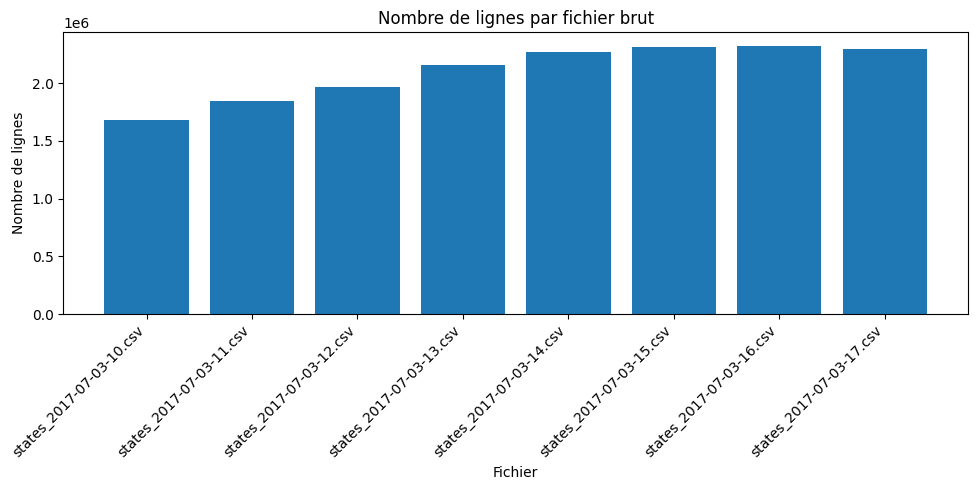

In [13]:
plt.figure(figsize=(10, 5))
plt.bar(volume_df["file"], volume_df["n_rows"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Fichier")
plt.ylabel("Nombre de lignes")
plt.title("Nombre de lignes par fichier brut")
plt.tight_layout()
plt.show()

**Lecture du résultat :**

Ce graphique permet de vérifier si les fichiers horaires ont des volumes comparables.  
Une forte différence peut indiquer une heure avec moins de trafic ou un problème de fichier.

# 8. Analyse temporelle

Nous vérifions maintenant la période couverte par chaque fichier.

Chaque fichier doit normalement correspondre à environ une heure d’observations.

In [14]:
time_df = raw_overview_df[[
    "file",
    "min_datetime",
    "max_datetime",
    "duration_minutes"
]].copy()

time_df

,file,min_datetime,max_datetime,duration_minutes
0,states_2017-07-03-10.csv,2017-07-03 10:00:00,2017-07-03 10:59:50,59.83
1,states_2017-07-03-11.csv,2017-07-03 11:00:00,2017-07-03 11:59:50,59.83
2,states_2017-07-03-12.csv,2017-07-03 12:00:00,2017-07-03 12:59:50,59.83
3,states_2017-07-03-13.csv,2017-07-03 13:00:00,2017-07-03 13:59:50,59.83
4,states_2017-07-03-14.csv,2017-07-03 14:00:00,2017-07-03 14:59:50,59.83
5,states_2017-07-03-15.csv,2017-07-03 15:00:00,2017-07-03 15:59:50,59.83
6,states_2017-07-03-16.csv,2017-07-03 16:00:00,2017-07-03 16:59:50,59.83
7,states_2017-07-03-17.csv,2017-07-03 17:00:00,2017-07-03 17:59:50,59.83


**Lecture du résultat :**

- `min_datetime` indique le début de la période couverte par le fichier.
- `max_datetime` indique la fin de la période couverte.
- `duration_minutes` doit être proche de 60 minutes pour chaque fichier horaire.

Cette vérification confirme que les 8 fichiers couvrent bien la période attendue.

# 9. Analyse des avions observés

Nous analysons maintenant les avions présents dans les fichiers.

Cette analyse est importante car certains avions peuvent apparaître dans plusieurs fichiers horaires.  
Cela justifie le fait de reconstruire les trajectoires sur les 8 heures plutôt que de traiter chaque heure de manière complètement indépendante.

In [15]:
aircraft_count_df = pd.DataFrame({
    "file": list(aircraft_sets.keys()),
    "n_aircraft": [len(s) for s in aircraft_sets.values()]
})

aircraft_count_df

,file,n_aircraft
0,states_2017-07-03-10.csv,9363
1,states_2017-07-03-11.csv,10368
2,states_2017-07-03-12.csv,11355
3,states_2017-07-03-13.csv,12538
4,states_2017-07-03-14.csv,13351
5,states_2017-07-03-15.csv,13807
6,states_2017-07-03-16.csv,13992
7,states_2017-07-03-17.csv,13928


In [16]:
all_aircraft = set()

for aircraft_set in aircraft_sets.values():
    all_aircraft.update(aircraft_set)

print("Nombre total d'avions uniques sur les fichiers :", len(all_aircraft))

Nombre total d'avions uniques sur les fichiers : 32294


In [17]:
aircraft_counter = Counter()

for aircraft_set in aircraft_sets.values():
    aircraft_counter.update(aircraft_set)

aircraft_presence_df = pd.DataFrame(
    aircraft_counter.items(),
    columns=["icao24", "n_files_present"]
)

aircraft_presence_df.sort_values("n_files_present", ascending=False).head(10)

,icao24,n_files_present
43,400db3,8
1,484ee5,8
42,7c432d,8
13,896ed1,8
5,4ca7b9,8
3107,4ca96e,8
3257,45c261,8
54,e48415,8
3213,400a35,8
3208,47878e,8


In [18]:
aircraft_presence_df["n_files_present"].describe()

,n_files_present
count,32294.000000
mean,3.056357
std,2.113972
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,8.000000


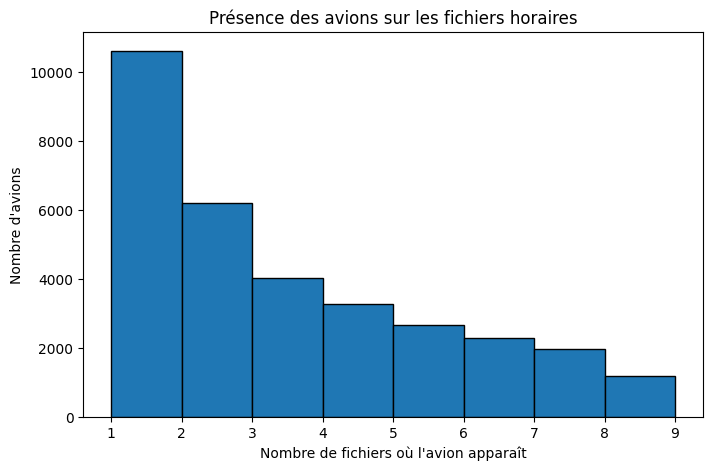

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(aircraft_presence_df["n_files_present"], bins=range(1, len(csv_files) + 2), edgecolor="black")
plt.xlabel("Nombre de fichiers où l'avion apparaît")
plt.ylabel("Nombre d'avions")
plt.title("Présence des avions sur les fichiers horaires")
plt.show()

**Lecture du résultat :**

Si plusieurs avions apparaissent dans plusieurs fichiers, cela signifie que certaines trajectoires traversent plusieurs heures.  
Dans le notebook de preprocessing, nous devrons donc concaténer les données nettoyées puis trier globalement par avion et par temps.

# 10. Analyse des valeurs manquantes

Nous analysons les valeurs manquantes par colonne.

Cette étape permet d’identifier les colonnes les plus incomplètes et de préparer les règles de nettoyage.

In [20]:
missing_by_column = (
    missing_df
    .groupby("column")
    .agg(
        mean_missing_pct=("missing_pct", "mean"),
        max_missing_pct=("missing_pct", "max"),
        min_missing_pct=("missing_pct", "min")
    )
    .reset_index()
    .sort_values("mean_missing_pct", ascending=False)
)

missing_by_column

,column,mean_missing_pct,max_missing_pct,min_missing_pct
3,geoaltitude,30.528761,32.630086,26.227437
2,callsign,27.604640,31.920361,20.268773
4,heading,25.988239,27.951353,21.820691
14,velocity,25.988239,27.951353,21.820691
8,lat,25.569552,27.456770,21.414978
9,lon,25.569552,27.456770,21.414978
7,lastposupdate,25.569552,27.456770,21.414978
15,vertrate,24.855031,26.631630,21.332589
12,squawk,9.681876,11.950405,7.301106
1,baroaltitude,6.112140,6.523859,5.675517


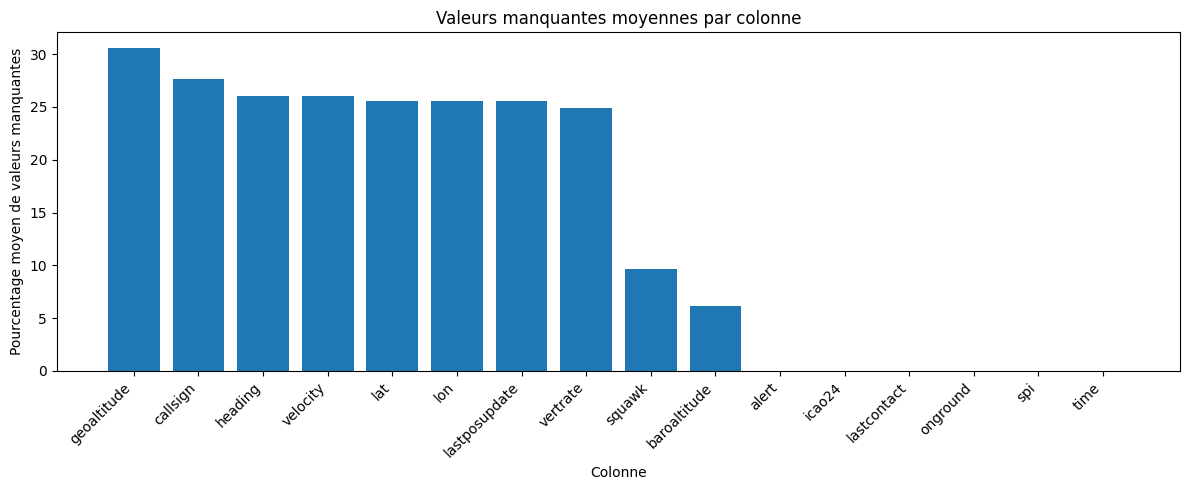

In [21]:
plt.figure(figsize=(12, 5))
plt.bar(missing_by_column["column"], missing_by_column["mean_missing_pct"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Colonne")
plt.ylabel("Pourcentage moyen de valeurs manquantes")
plt.title("Valeurs manquantes moyennes par colonne")
plt.tight_layout()
plt.show()

In [22]:
# Affichage ciblé des colonnes importantes pour la trajectoire
important_columns = [
    "time", "icao24", "lat", "lon", "velocity", "heading",
    "vertrate", "baroaltitude", "geoaltitude"
]

missing_important = missing_by_column[
    missing_by_column["column"].isin(important_columns)
].copy()

missing_important

,column,mean_missing_pct,max_missing_pct,min_missing_pct
3,geoaltitude,30.528761,32.630086,26.227437
4,heading,25.988239,27.951353,21.820691
14,velocity,25.988239,27.951353,21.820691
8,lat,25.569552,27.456770,21.414978
9,lon,25.569552,27.456770,21.414978
15,vertrate,24.855031,26.631630,21.332589
1,baroaltitude,6.112140,6.523859,5.675517
5,icao24,0.000000,0.000000,0.000000
13,time,0.000000,0.000000,0.000000


**Lecture du résultat :**

Les colonnes critiques pour construire une trajectoire sont notamment `time`, `icao24`, `lat`, `lon`, `velocity`, `heading` et les colonnes d’altitude.  
Les lignes où ces informations sont absentes devront être traitées ou supprimées dans le notebook de preprocessing.

# 11. Analyse statistique des variables numériques

Nous analysons les statistiques descriptives sur un échantillon global.

Pour éviter de charger toutes les données en même temps, nous prenons un échantillon de chaque fichier.

In [23]:
N_SAMPLE_PER_FILE = 100_000
sample_parts = []

for file in csv_files:
    print("Échantillonnage :", file.name)
    df_sample = pd.read_csv(file, nrows=N_SAMPLE_PER_FILE)
    df_sample["source_file"] = file.name
    sample_parts.append(df_sample)

df_sample_all = pd.concat(sample_parts, ignore_index=True)

print("Taille de l'échantillon global :", df_sample_all.shape)

Échantillonnage : states_2017-07-03-10.csv
Échantillonnage : states_2017-07-03-11.csv
Échantillonnage : states_2017-07-03-12.csv
Échantillonnage : states_2017-07-03-13.csv
Échantillonnage : states_2017-07-03-14.csv
Échantillonnage : states_2017-07-03-15.csv
Échantillonnage : states_2017-07-03-16.csv
Échantillonnage : states_2017-07-03-17.csv
Taille de l'échantillon global : (800000, 17)


In [24]:
numeric_cols = df_sample_all.select_dtypes(include=[np.number]).columns.tolist()

print("Colonnes numériques détectées :")
for col in numeric_cols:
    print("-", col)

Colonnes numériques détectées :
- time
- lat
- lon
- velocity
- heading
- vertrate
- squawk
- baroaltitude
- geoaltitude
- lastposupdate
- lastcontact


In [25]:
# Statistiques sur les variables numériques importantes pour la trajectoire
trajectory_numeric_cols = [
    col for col in ["lat", "lon", "velocity", "heading", "vertrate", "baroaltitude", "geoaltitude"]
    if col in df_sample_all.columns
]

df_sample_all[trajectory_numeric_cols].describe()

,lat,lon,velocity,heading,vertrate,baroaltitude,geoaltitude
count,541875.000000,541875.000000,544165.000000,544165.000000,550081.000000,756382.000000,519136.000000
mean,42.057500,-14.391720,197.007027,189.856484,0.082282,7408.058337,8401.345077
std,15.014049,55.798825,64.606938,101.708959,30.743304,4258.011263,3946.929508
min,-37.709501,-155.776978,0.000000,-0.000000,-1891.665000,-304.800000,-533.400000
25%,39.469501,-74.181442,170.995181,102.750026,-0.325120,3253.740000,5212.080000
50%,44.594251,3.788773,218.017458,199.004632,0.000000,9144.000000,10332.720000
75%,50.142640,14.552417,237.877927,279.183919,0.325120,10972.800000,11475.720000
max,67.604507,175.838070,2259.326536,359.888962,1756.410000,38557.200000,38709.600000


**Lecture du résultat :**

Les statistiques descriptives permettent de vérifier les ordres de grandeur :

- latitude entre -90 et 90 ;
- longitude entre -180 et 180 ;
- vitesse positive ;
- heading entre 0 et 360 ;
- altitude dans un intervalle réaliste.

Les valeurs incohérentes seront filtrées dans le notebook de preprocessing.

# 12. Détection des valeurs impossibles

Nous vérifions la présence de valeurs physiquement impossibles :

- latitude hors de l’intervalle `[-90, 90]` ;
- longitude hors de l’intervalle `[-180, 180]` ;
- vitesse négative ;
- heading hors de l’intervalle `[0, 360]`.

In [27]:
invalid_df

,file,n_rows,lat_invalid,lon_invalid,velocity_negative,heading_invalid
0,states_2017-07-03-10.csv,1684690,0,0,0,0
1,states_2017-07-03-11.csv,1849076,0,0,0,0
2,states_2017-07-03-12.csv,1970582,0,0,0,0
3,states_2017-07-03-13.csv,2159702,0,0,0,0
4,states_2017-07-03-14.csv,2267582,0,0,0,0
5,states_2017-07-03-15.csv,2314879,0,0,0,0
6,states_2017-07-03-16.csv,2324633,0,0,0,0
7,states_2017-07-03-17.csv,2296600,0,0,0,0


In [28]:
invalid_totals = invalid_df.drop(columns=["file", "n_rows"]).sum(numeric_only=True)
invalid_totals

,0
lat_invalid,0
lon_invalid,0
velocity_negative,0
heading_invalid,0


In [29]:
invalid_pct_df = invalid_df.copy()

for col in ["lat_invalid", "lon_invalid", "velocity_negative", "heading_invalid"]:
    invalid_pct_df[col + "_pct"] = invalid_pct_df[col] / invalid_pct_df["n_rows"] * 100

invalid_pct_df

,file,n_rows,lat_invalid,lon_invalid,velocity_negative,heading_invalid,lat_invalid_pct,lon_invalid_pct,velocity_negative_pct,heading_invalid_pct
0,states_2017-07-03-10.csv,1684690,0,0,0,0,0.0,0.0,0.0,0.0
1,states_2017-07-03-11.csv,1849076,0,0,0,0,0.0,0.0,0.0,0.0
2,states_2017-07-03-12.csv,1970582,0,0,0,0,0.0,0.0,0.0,0.0
3,states_2017-07-03-13.csv,2159702,0,0,0,0,0.0,0.0,0.0,0.0
4,states_2017-07-03-14.csv,2267582,0,0,0,0,0.0,0.0,0.0,0.0
5,states_2017-07-03-15.csv,2314879,0,0,0,0,0.0,0.0,0.0,0.0
6,states_2017-07-03-16.csv,2324633,0,0,0,0,0.0,0.0,0.0,0.0
7,states_2017-07-03-17.csv,2296600,0,0,0,0,0.0,0.0,0.0,0.0


**Lecture du résultat :**

Les valeurs impossibles détectées ne seront pas utilisées pour construire les trajectoires.  
Elles seront supprimées dans le notebook `02_preprocessing_features.ipynb`.

# 13. Analyse des colonnes d’altitude

Le dataset contient généralement deux colonnes d’altitude :

- `geoaltitude` ;
- `baroaltitude`.

L’objectif est de vérifier leur disponibilité afin de créer plus tard une seule colonne `altitude`.

In [30]:
altitude_df

,file,n_rows,baro_missing_pct,geo_missing_pct,both_altitudes_missing_pct
0,states_2017-07-03-10.csv,1684690,6.200191,26.227437,6.198529
1,states_2017-07-03-11.csv,1849076,6.070437,27.355176,6.070221
2,states_2017-07-03-12.csv,1970582,6.523859,30.452780,6.522540
3,states_2017-07-03-13.csv,2159702,6.039074,31.129156,6.037222
4,states_2017-07-03-14.csv,2267582,5.675517,31.847713,5.673577
5,states_2017-07-03-15.csv,2314879,5.907609,32.630086,5.903678
6,states_2017-07-03-16.csv,2324633,6.030285,32.247542,6.027274
7,states_2017-07-03-17.csv,2296600,6.450144,32.340199,6.447444


In [31]:
if len(altitude_df) > 0:
    altitude_mean = altitude_df[["baro_missing_pct", "geo_missing_pct", "both_altitudes_missing_pct"]].mean()
    altitude_mean
else:
    print("Les colonnes d'altitude attendues ne sont pas disponibles.")

**Décision pour le preprocessing :**

Dans le notebook suivant, nous créerons une colonne unique :

```python
altitude = geoaltitude si disponible, sinon baroaltitude
```

Ensuite, les lignes sans aucune altitude disponible seront supprimées.

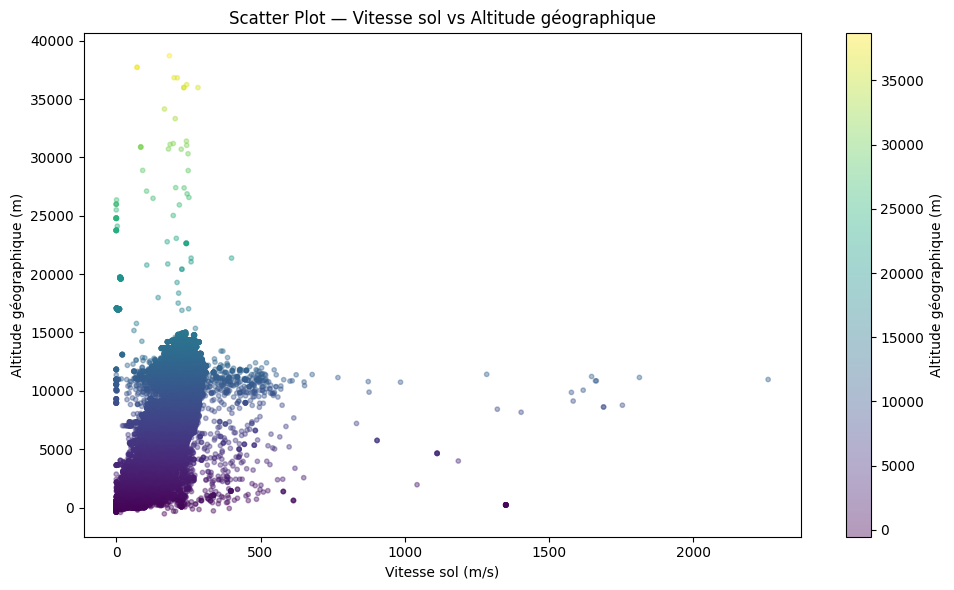

In [32]:
# ============================================================
# SCATTER PLOT — Vitesse sol vs Altitude géographique
# ============================================================
required_cols_scatter = {"velocity", "geoaltitude", "icao24"}

if required_cols_scatter.issubset(df_sample_all.columns):
    df_scatter = df_sample_all.dropna(subset=["velocity", "geoaltitude"]).copy()

    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(
        df_scatter["velocity"],
        df_scatter["geoaltitude"],
        c=df_scatter["geoaltitude"],
        cmap="viridis",
        alpha=0.4,
        s=10
    )
    plt.colorbar(scatter, label="Altitude géographique (m)")
    plt.xlabel("Vitesse sol (m/s)")
    plt.ylabel("Altitude géographique (m)")
    plt.title("Scatter Plot — Vitesse sol vs Altitude géographique")
    plt.tight_layout()

    # ✅ savefig dans la même cellule, avant show
    plt.savefig(FIGURES_DIR / "scatter_velocity_vs_altitude.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

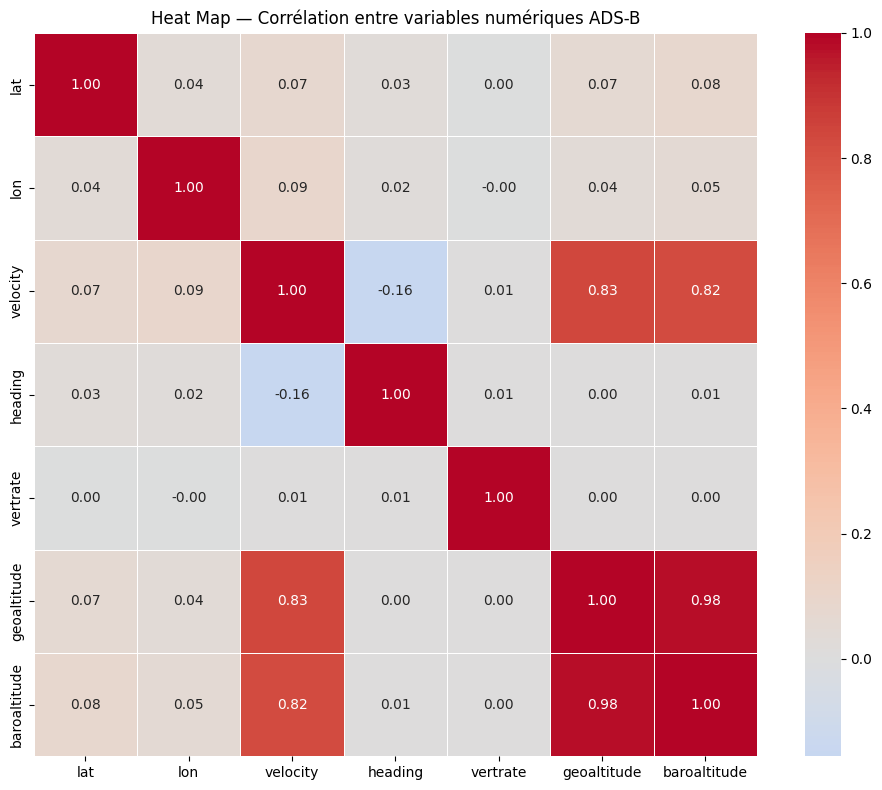

In [33]:
# ============================================================
# HEAT MAP — Matrice de corrélation
# ============================================================
import seaborn as sns

numeric_cols = [
    "lat", "lon", "velocity", "heading",
    "vertrate", "geoaltitude", "baroaltitude"
]

available_numeric_cols = [c for c in numeric_cols if c in df_sample_all.columns]

df_corr = df_sample_all[available_numeric_cols].dropna()
corr_matrix = df_corr.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Heat Map — Corrélation entre variables numériques ADS-B")
plt.tight_layout()

# ✅ savefig dans la même cellule
plt.savefig(FIGURES_DIR / "heatmap_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

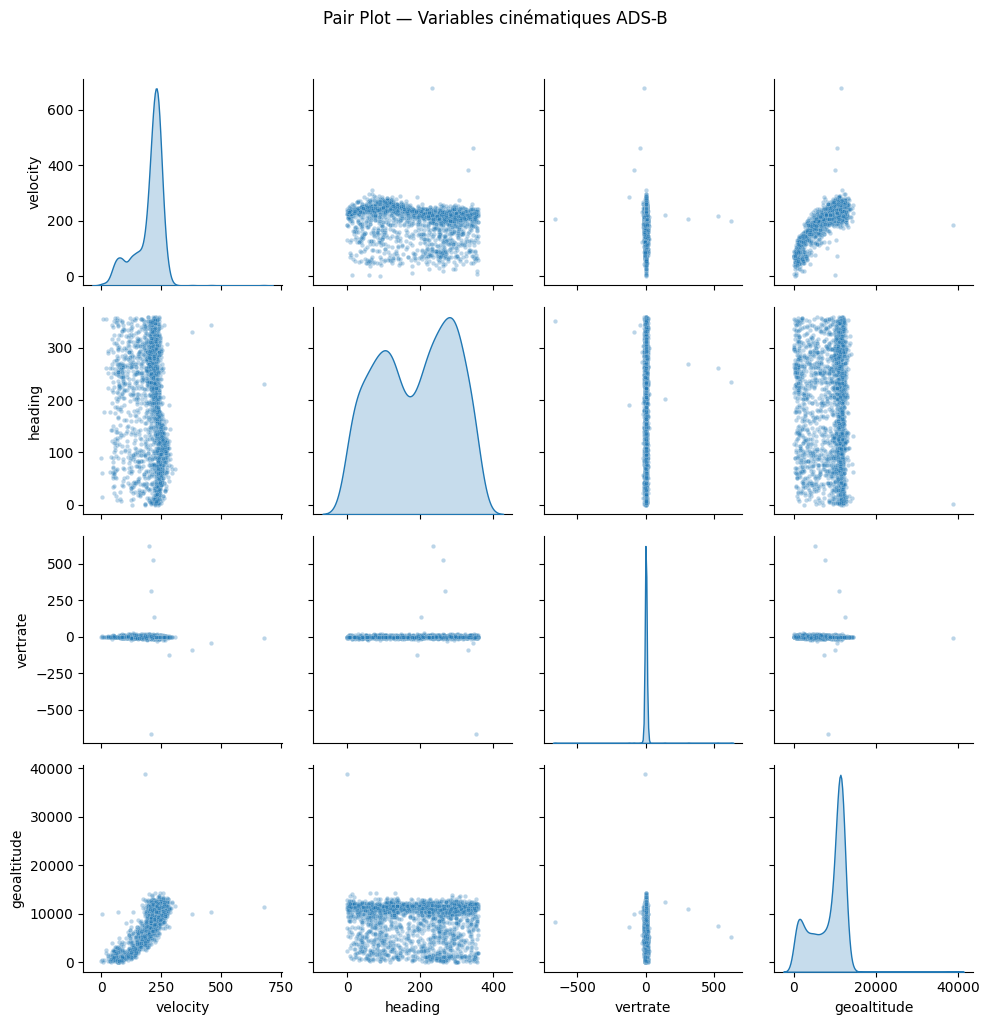

In [34]:
# ============================================================
# PAIR PLOT — Relations croisées entre variables clés
# ============================================================
import seaborn as sns

pair_cols = ["velocity", "heading", "vertrate", "geoaltitude"]
available_pair_cols = [c for c in pair_cols if c in df_sample_all.columns]

df_pair = df_sample_all[available_pair_cols].dropna()
df_pair_sample = df_pair.sample(min(2000, len(df_pair)), random_state=42)

pair_grid = sns.pairplot(
    df_pair_sample,
    diag_kind="kde",
    plot_kws={"alpha": 0.3, "s": 10},
    diag_kws={"fill": True}
)
pair_grid.figure.suptitle("Pair Plot — Variables cinématiques ADS-B", y=1.02)
plt.tight_layout()

# ✅ savefig dans la même cellule — utiliser pair_grid.figure pour le pairplot
pair_grid.figure.savefig(FIGURES_DIR / "pairplot_cinematique.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

/tmp/ipykernel_2014/4061624712.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


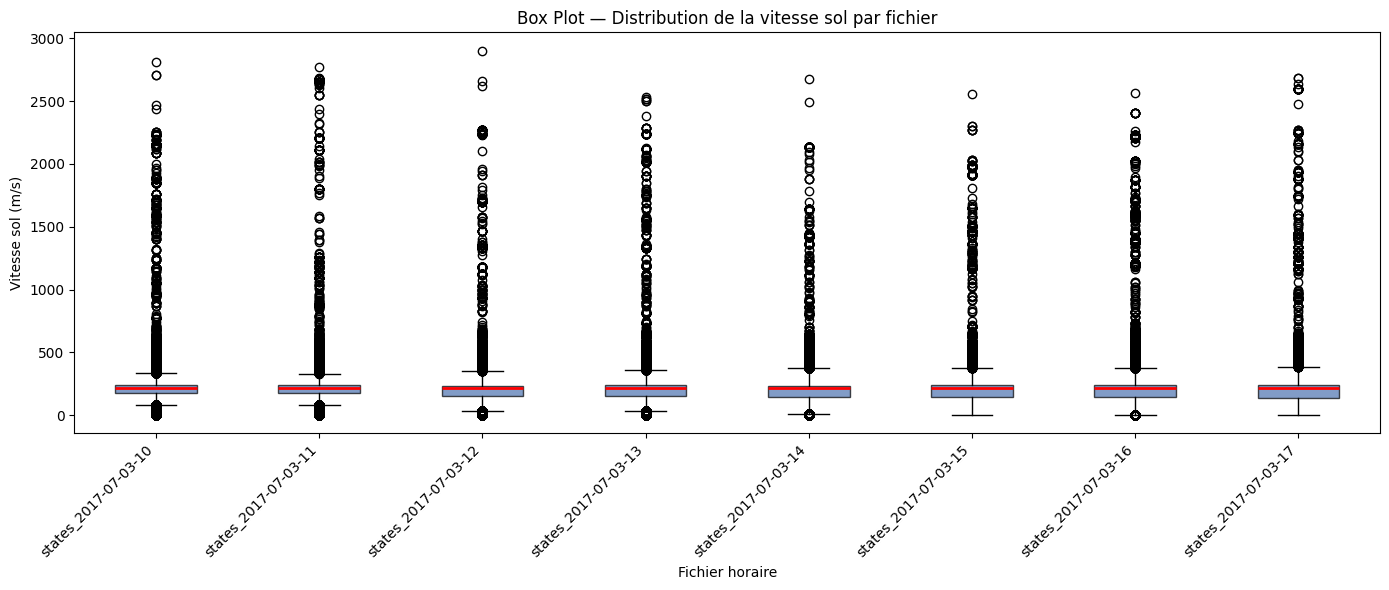

In [35]:
# ============================================================
# BOX PLOT — Distribution de la vitesse sol par fichier horaire
# ============================================================
box_data = []

for file in csv_files:
    df_tmp = pd.read_csv(file)
    if "velocity" in df_tmp.columns:
        df_tmp["source_file"] = file.name
        box_data.append(df_tmp[["velocity", "source_file"]].dropna())

df_box = pd.concat(box_data, ignore_index=True)

file_labels = [f.name.replace(".csv", "") for f in csv_files]
data_per_file = [
    df_box[df_box["source_file"] == f.name]["velocity"].values
    for f in csv_files
]

plt.figure(figsize=(14, 6))
plt.boxplot(
    data_per_file,
    labels=file_labels,
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", alpha=0.7),
    medianprops=dict(color="red", linewidth=2)
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Fichier horaire")
plt.ylabel("Vitesse sol (m/s)")
plt.title("Box Plot — Distribution de la vitesse sol par fichier")
plt.tight_layout()

# ✅ savefig dans la même cellule
plt.savefig(FIGURES_DIR / "boxplot_velocity_par_fichier.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

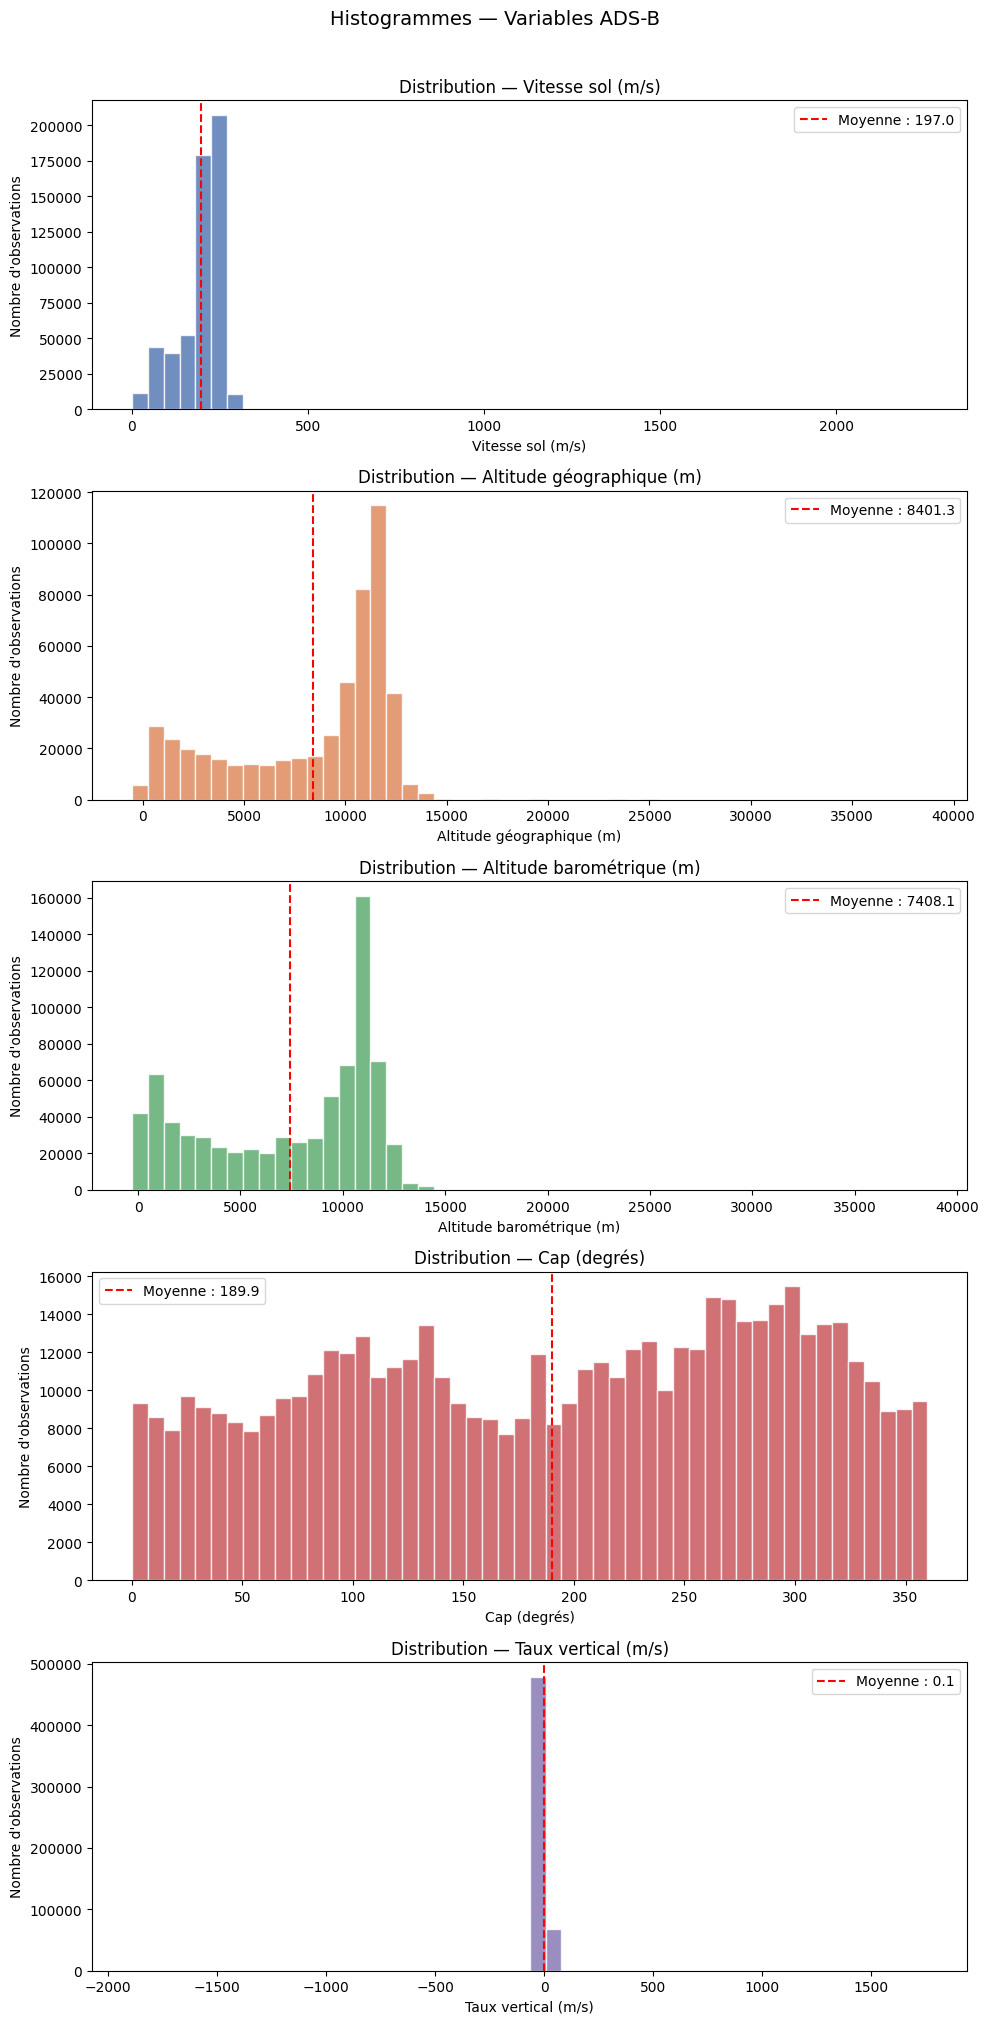

Histogrammes sauvegardés : 240 KB


In [36]:
# ============================================================
# HISTOGRAMMES — Distribution des variables ADS-B
# ============================================================

hist_cols = {
    "velocity":     ("Vitesse sol (m/s)",          "#4C72B0"),
    "geoaltitude":  ("Altitude géographique (m)",   "#DD8452"),
    "baroaltitude": ("Altitude barométrique (m)",   "#55A868"),
    "heading":      ("Cap (degrés)",                "#C44E52"),
    "vertrate":     ("Taux vertical (m/s)",         "#8172B2"),
}

# On garde uniquement les colonnes présentes dans le dataset
available_hist_cols = {
    col: (label, color)
    for col, (label, color) in hist_cols.items()
    if col in df_sample_all.columns
}

fig, axes = plt.subplots(
    nrows=len(available_hist_cols),
    ncols=1,
    figsize=(10, 4 * len(available_hist_cols))
)

# Si une seule colonne disponible, axes n'est pas une liste
if len(available_hist_cols) == 1:
    axes = [axes]

for ax, (col, (label, color)) in zip(axes, available_hist_cols.items()):
    data = df_sample_all[col].dropna()

    ax.hist(
        data,
        bins=50,
        color=color,
        alpha=0.8,
        edgecolor="white"
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Nombre d'observations")
    ax.set_title(f"Distribution — {label}")

    # Ligne verticale pour la moyenne
    mean_val = data.mean()
    ax.axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Moyenne : {mean_val:.1f}")
    ax.legend()

plt.suptitle("Histogrammes — Variables ADS-B", fontsize=14, y=1.01)
plt.tight_layout()

# ✅ savefig dans la même cellule
plt.savefig(FIGURES_DIR / "histogrammes_variables_adsb.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Histogrammes sauvegardés :", (FIGURES_DIR / "histogrammes_variables_adsb.png").stat().st_size // 1024, "KB")

# 14. Visualisation rapide de trajectoires brutes

Nous visualisons quelques trajectoires afin de vérifier qualitativement que les positions forment bien des mouvements cohérents.

Cette visualisation reste brute : les données ne sont pas encore nettoyées ni resamplées.

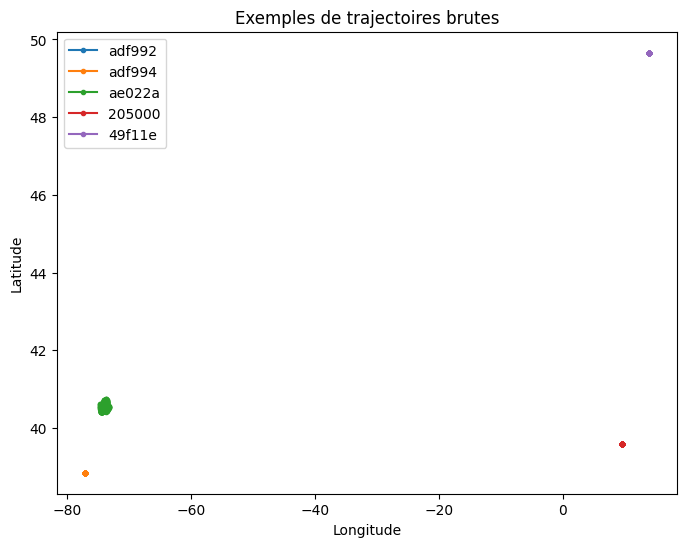

In [37]:
required_cols = {"icao24", "lat", "lon", "time"}

if required_cols.issubset(df_sample_all.columns):
    df_plot = df_sample_all.dropna(subset=["icao24", "lat", "lon", "time"]).copy()
    df_plot["datetime"] = pd.to_datetime(df_plot["time"], unit="s")
    df_plot = df_plot.sort_values(["icao24", "datetime"])

    top_aircraft = df_plot["icao24"].value_counts().head(5).index

    plt.figure(figsize=(8, 6))

    for icao in top_aircraft:
        traj = df_plot[df_plot["icao24"] == icao]
        plt.plot(traj["lon"], traj["lat"], marker=".", linestyle="-", label=str(icao))

    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Exemples de trajectoires brutes")
    plt.legend()
    plt.show()
else:
    print("Colonnes nécessaires absentes pour tracer les trajectoires.")

**Lecture du résultat :**

Le graphique doit montrer des trajectoires géographiques.  
Des trajectoires bruitées ou coupées sont normales à ce stade, car le nettoyage et le resampling ne sont pas encore appliqués.

# 15. Analyse de l’irrégularité temporelle

Les données ADS-B brutes ne sont pas forcément espacées régulièrement dans le temps.

Nous analysons les écarts temporels entre deux observations successives pour vérifier si un resampling est nécessaire.

,time_diff_sec
count,528115.000000
mean,226.730864
std,1362.613712
min,10.000000
25%,10.000000
50%,10.000000
75%,10.000000
max,25130.000000


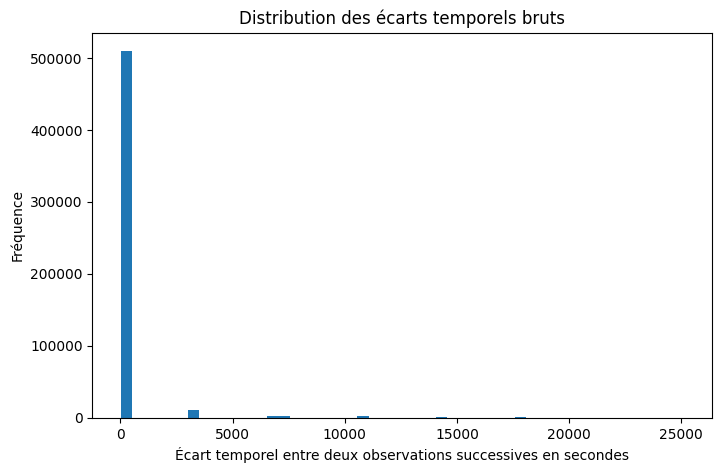

In [38]:
if {"time", "icao24", "lat", "lon"}.issubset(df_sample_all.columns):
    df_time = df_sample_all.dropna(subset=["time", "icao24", "lat", "lon"]).copy()
    df_time["datetime"] = pd.to_datetime(df_time["time"], unit="s")
    df_time = df_time.sort_values(["icao24", "datetime"])

    df_time["time_diff_sec"] = (
        df_time.groupby("icao24")["datetime"]
        .diff()
        .dt.total_seconds()
    )

    display(df_time["time_diff_sec"].describe())

    plt.figure(figsize=(8, 5))
    plt.hist(df_time["time_diff_sec"].dropna(), bins=50)
    plt.xlabel("Écart temporel entre deux observations successives en secondes")
    plt.ylabel("Fréquence")
    plt.title("Distribution des écarts temporels bruts")
    plt.show()
else:
    print("Colonnes nécessaires absentes pour analyser l'irrégularité temporelle.")

**Lecture du résultat :**

Si les écarts temporels sont très variables, cela confirme qu’un resampling est nécessaire.  
Dans le notebook suivant, nous utiliserons un resampling régulier, par exemple un point toutes les 10 secondes.

In [42]:
# ============================================================
# BILAN DE L'EXPLORATION — shape et qualité des données
# ============================================================
print("=" * 50)
print("BILAN DE L'EXPLORATION")
print("=" * 50)
print(f"Nombre de lignes         : {df_sample_all.shape[0]:,}")
print(f"Nombre de colonnes       : {df_sample_all.shape[1]}")

print()
print("Valeurs manquantes par colonne :")
missing = df_sample_all.isna().sum()
missing_pct = (missing / len(df_sample_all) * 100).round(2)
for col in missing[missing > 0].index:
    print(f"  - {col:<20} : {missing[col]:,} manquantes ({missing_pct[col]}%)")

print()
print(f"Doublons détectés        : {df_sample_all.duplicated().sum():,}")
print(f"Avions uniques (icao24)  : {df_sample_all['icao24'].nunique():,}")

print()
print("=" * 50)
print("OBSERVATIONS — à traiter dans 02_preprocessing")
print("=" * 50)
print("→ Supprimer les lignes avec lat/lon/time manquants")
print("→ Filtrer les valeurs impossibles (vitesse négative, etc.)")
print("→ Fusionner geoaltitude et baroaltitude")
print("→ Resampler les trajectoires à fréquence régulière")
print("→ Trier par icao24 et time")

BILAN DE L'EXPLORATION
Nombre de lignes         : 800,000
Nombre de colonnes       : 17

Valeurs manquantes par colonne :
  - lat                  : 258,125 manquantes (32.27%)
  - lon                  : 258,125 manquantes (32.27%)
  - velocity             : 255,835 manquantes (31.98%)
  - heading              : 255,835 manquantes (31.98%)
  - vertrate             : 249,919 manquantes (31.24%)
  - callsign             : 268,352 manquantes (33.54%)
  - squawk               : 104,810 manquantes (13.1%)
  - baroaltitude         : 43,618 manquantes (5.45%)
  - geoaltitude          : 280,864 manquantes (35.11%)
  - lastposupdate        : 258,125 manquantes (32.27%)

Doublons détectés        : 0
Avions uniques (icao24)  : 20,624

OBSERVATIONS — à traiter dans 02_preprocessing
→ Supprimer les lignes avec lat/lon/time manquants
→ Filtrer les valeurs impossibles (vitesse négative, etc.)
→ Fusionner geoaltitude et baroaltitude
→ Resampler les trajectoires à fréquence régulière
→ Trier par icao24

# 16. Synthèse de l’exploration

Nous résumons les principaux problèmes observés et les traitements prévus dans le notebook suivant.

In [40]:
synthesis = pd.DataFrame({
    "Observation": [
        "Fichiers horaires multiples",
        "Avions présents dans plusieurs fichiers",
        "Valeurs manquantes dans certaines colonnes",
        "Deux colonnes d'altitude disponibles",
        "Valeurs physiques impossibles possibles",
        "Observations temporelles irrégulières",
        "Trajectoires brutes parfois bruitées ou incomplètes"
    ],
    "Conséquence": [
        "Les fichiers doivent être traités avec une méthode commune",
        "Les trajectoires ne doivent pas être coupées artificiellement à chaque heure",
        "Certaines lignes devront être supprimées ou traitées",
        "Une colonne altitude unique doit être créée",
        "Des règles de filtrage physique sont nécessaires",
        "Un resampling temporel régulier est nécessaire",
        "Des features robustes devront être calculées après nettoyage"
    ],
    "Traitement prévu": [
        "Utiliser une boucle sur les fichiers",
        "Concaténer après nettoyage et trier par avion et par temps",
        "Supprimer les lignes sans informations critiques",
        "altitude = geoaltitude sinon baroaltitude",
        "Filtrer lat/lon/vitesse/heading impossibles",
        "Resampling à 10 secondes",
        "Feature engineering après resampling"
    ]
})

synthesis

,Observation,Conséquence,Traitement prévu
0,Fichiers horaires multiples,Les fichiers doivent être traités avec une mét...,Utiliser une boucle sur les fichiers
1,Avions présents dans plusieurs fichiers,Les trajectoires ne doivent pas être coupées a...,Concaténer après nettoyage et trier par avion ...
2,Valeurs manquantes dans certaines colonnes,Certaines lignes devront être supprimées ou tr...,Supprimer les lignes sans informations critiques
3,Deux colonnes d'altitude disponibles,Une colonne altitude unique doit être créée,altitude = geoaltitude sinon baroaltitude
4,Valeurs physiques impossibles possibles,Des règles de filtrage physique sont nécessaires,Filtrer lat/lon/vitesse/heading impossibles
5,Observations temporelles irrégulières,Un resampling temporel régulier est nécessaire,Resampling à 10 secondes
6,Trajectoires brutes parfois bruitées ou incomp...,Des features robustes devront être calculées a...,Feature engineering après resampling


# 17. Sauvegarde des résultats d’exploration

Nous sauvegardons les tableaux importants dans `results/metrics/` pour pouvoir les réutiliser dans le rapport technique.

In [41]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

columns_df.to_csv(METRICS_DIR / "exploration_columns_summary.csv", index=False)
expected_columns_df.to_csv(METRICS_DIR / "exploration_expected_columns_check.csv", index=False)
volume_df.to_csv(METRICS_DIR / "exploration_volume_summary.csv", index=False)
time_df.to_csv(METRICS_DIR / "exploration_time_summary.csv", index=False)
aircraft_count_df.to_csv(METRICS_DIR / "exploration_aircraft_count_summary.csv", index=False)
aircraft_presence_df.to_csv(METRICS_DIR / "exploration_aircraft_presence_summary.csv", index=False)
missing_by_column.to_csv(METRICS_DIR / "exploration_missing_by_column.csv", index=False)
invalid_df.to_csv(METRICS_DIR / "exploration_invalid_values_summary.csv", index=False)
altitude_df.to_csv(METRICS_DIR / "exploration_altitude_summary.csv", index=False)
synthesis.to_csv(METRICS_DIR / "exploration_synthesis.csv", index=False)

print("Résumés sauvegardés dans :", METRICS_DIR)

Résumés sauvegardés dans : /content/drive/MyDrive/aircraft-trajectory-prediction/results/metrics


# 18. Conclusion du notebook

Cette exploration montre que les données brutes sont exploitables, mais qu’elles nécessitent plusieurs traitements avant la modélisation :

1. sélectionner les colonnes utiles ;
2. créer une colonne `altitude` unique ;
3. supprimer les lignes sans position, vitesse, direction ou altitude ;
4. filtrer les valeurs physiquement impossibles ;
5. concaténer les fichiers nettoyés ;
6. trier les données par avion et par temps ;
7. créer des trajectoires continues ;
8. appliquer un resampling temporel régulier ;
9. créer des features cinématiques et géométriques.

La prochaine étape sera réalisée dans le notebook :

```text
02_preprocessing_features.ipynb
```

Ce prochain notebook produira le fichier :

```text
data/processed/features_clean.csv
```